In [1]:
import sys
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)

<module 'utils.plot_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/plot_utils.py'>

In [3]:
# read_ids = list(range(0, 8+1))
read_ids = [2]
plot_id = 2

In [4]:
# read
path = os.path.join(read_utils.get_data_path(), '6163622/sessions')
(file_ids, filenames,
 traces,
 continuous_behaviors,
 motion_pcs,
 motion_masks) = read_utils.get_datas(path, read_ids,
									  with_whisking=True)

# # clear nan values
for i in range(len(file_ids)):
	# mask = motion_pcs[i][0].notna().all(axis=1)
	mask = continuous_behaviors[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	motion_pcs[i][0] = motion_pcs[i][0][mask]
	motion_pcs[i][1] = motion_pcs[i][1][mask]
	continuous_behaviors[i] = continuous_behaviors[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
plot_idx = file_ids.index(plot_id)

# states = [ds[selection_bhl] for ds in states]

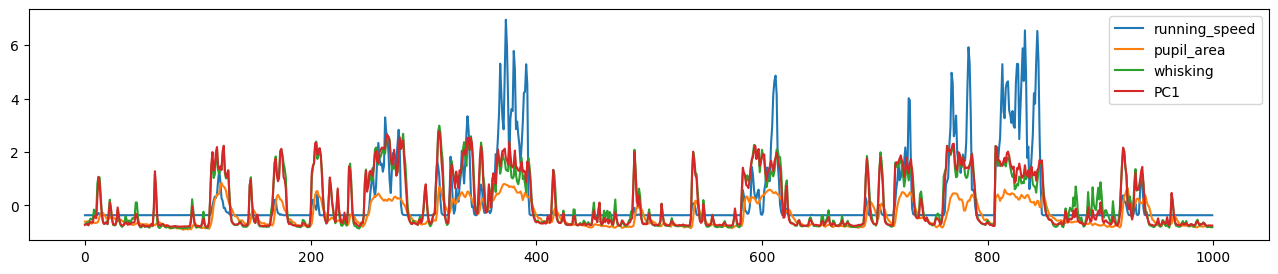

In [6]:
plt.figure(figsize=(16, 3))
DATA = [
		continuous_behaviors[plot_idx][['running_speed']],
		continuous_behaviors[plot_idx][['pupil_area']],
		continuous_behaviors[plot_idx][['whisking']],
		motion_pcs[plot_idx][0][['PC1']] * -1,
		]

for data in DATA:
	data -= data.mean(axis=0)
	data /= np.where((data_std := np.std(data, axis=0)) == 0.0, 1.0, data_std)
	plt.plot(data.values[:1000], label=data.columns[0])
plt.legend()

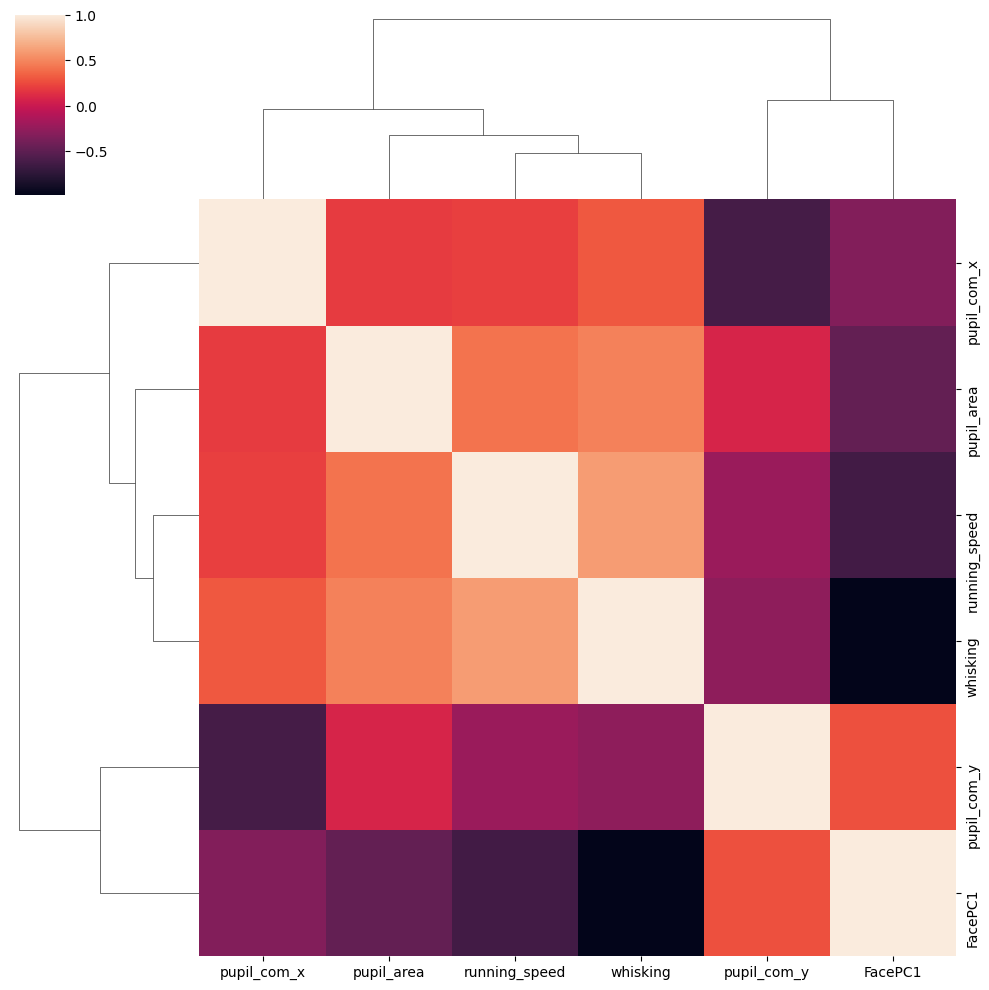

In [7]:
continuous_behaviors[plot_idx]['FacePC1'] = motion_pcs[plot_idx][0]['PC1'].values
corr = continuous_behaviors[plot_idx].corr()
sns.clustermap(continuous_behaviors[plot_idx].corr())